# Step 1: From a phone photo to training data

The 2nd-place model (Stage 2) never sees the raw competition images. It trains on **rectified** pages produced by
hengck23's Stage 0 and Stage 1, which the author reused without modification. This notebook follows one ECG record
through the whole data path:

```
raw photo/scan --Stage 0--> normalised page --Stage 1--> rectified page --(this repo)--> masks --> signal
```

**Before the pipeline**
1. What the competition provides (`train.csv`, 9 image types, ground-truth CSVs)

**Part A: Stages 0-1 (hengck23, reused unchanged)**

2. **Stage 0**: orientation and lead-label keypoints, then a homography (run live)
3. **Stage 1**: grid detection, then un-warping (run live, compared with the author's rectified image)

**Part B: Stage 2 (the 2nd-place author, Takashi Someya)**

4. The rectified frame: fixed geometry (Stage 1 output = Stage 2 input)
5. Ground-truth signals and how they map onto the 4 rows of the page
6. The training targets: sparse sub-pixel masks drawn from 500 Hz signals
7. Closing the loop: mask to signal to SNR

Needs the sample data (`python scripts/download_sample.py --originals`) and hengck23's code and weights in
`reference/hengck23-demo-submit-physionet/`. Runs in about 2 minutes on CPU.

In [1]:
import os, sys, contextlib, io, time
from pathlib import Path
if not Path('train.py').exists():   # allow running from notebooks/
    os.chdir('..')

import numpy as np, pandas as pd, cv2, torch, matplotlib.pyplot as plt
from scipy import signal

from src.data.mask_utils import load_sparse_mask
from src.data.transforms import resize_rectified, X_SCALE, RESIZED_W

HENG = Path('reference/hengck23-demo-submit-physionet')
sys.path.insert(0, str(HENG))
plt.rcParams['figure.dpi'] = 90
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('jpeg')          # keeps the notebook small

RECORD = '3056263433'          # a 500 Hz record from our sample (fold 4)
TYPES = ['0001', '0003', '0004', '0005', '0006', '0009', '0010', '0011', '0012']

def read_rgb(path):
    return cv2.imread(str(path), cv2.IMREAD_COLOR_RGB)

def thumb(img, width=900):
    s = width / img.shape[1]
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

def show(img, title=None, size=(14, 8)):
    plt.figure(figsize=size); plt.imshow(img); plt.axis('off')
    if title: plt.title(title)
    plt.show()

## 1. What the competition provides · *input data, before Stage 0*

`train.csv` has one row per ECG record: its sampling rate `fs` and signal length `sig_len` (always 10 s). The
signals come from the **PTB-XL** database, resampled by the organisers to six different rates.

In [2]:
train = pd.read_csv('data/competition/train.csv', dtype={'id': str})
print(len(train), 'records')
print(train.groupby(['fs', 'sig_len']).size().rename('records').to_string())
train[train.id == RECORD]

977 records
fs    sig_len
250   2500       163
256   2560       163
500   5000       163
512   5120       163
1000  10000      163
1025  10250      162


,id,fs,sig_len
677,3056263433,500,5000


Each record was printed and then re-captured in up to **9 ways** (the suffix of the image file). From the images in
our sample, the types look like this:

| type | what it looks like |
|---|---|
| 0001 | clean digital render, already 2200 × 1700 |
| 0003 | colour scan, slightly rotated |
| 0004 | black-and-white scan |
| 0005 | phone photo of the print lying on a carpet (perspective) |
| 0006 | phone photo of the ECG on a computer monitor (moiré, bezel) |
| 0009 | phone photo of stained / soiled paper |
| 0010 | phone photo of a B&W print on a table (shadows) |
| 0011 | colour scan, rotated |
| 0012 | B&W scan, rotated |

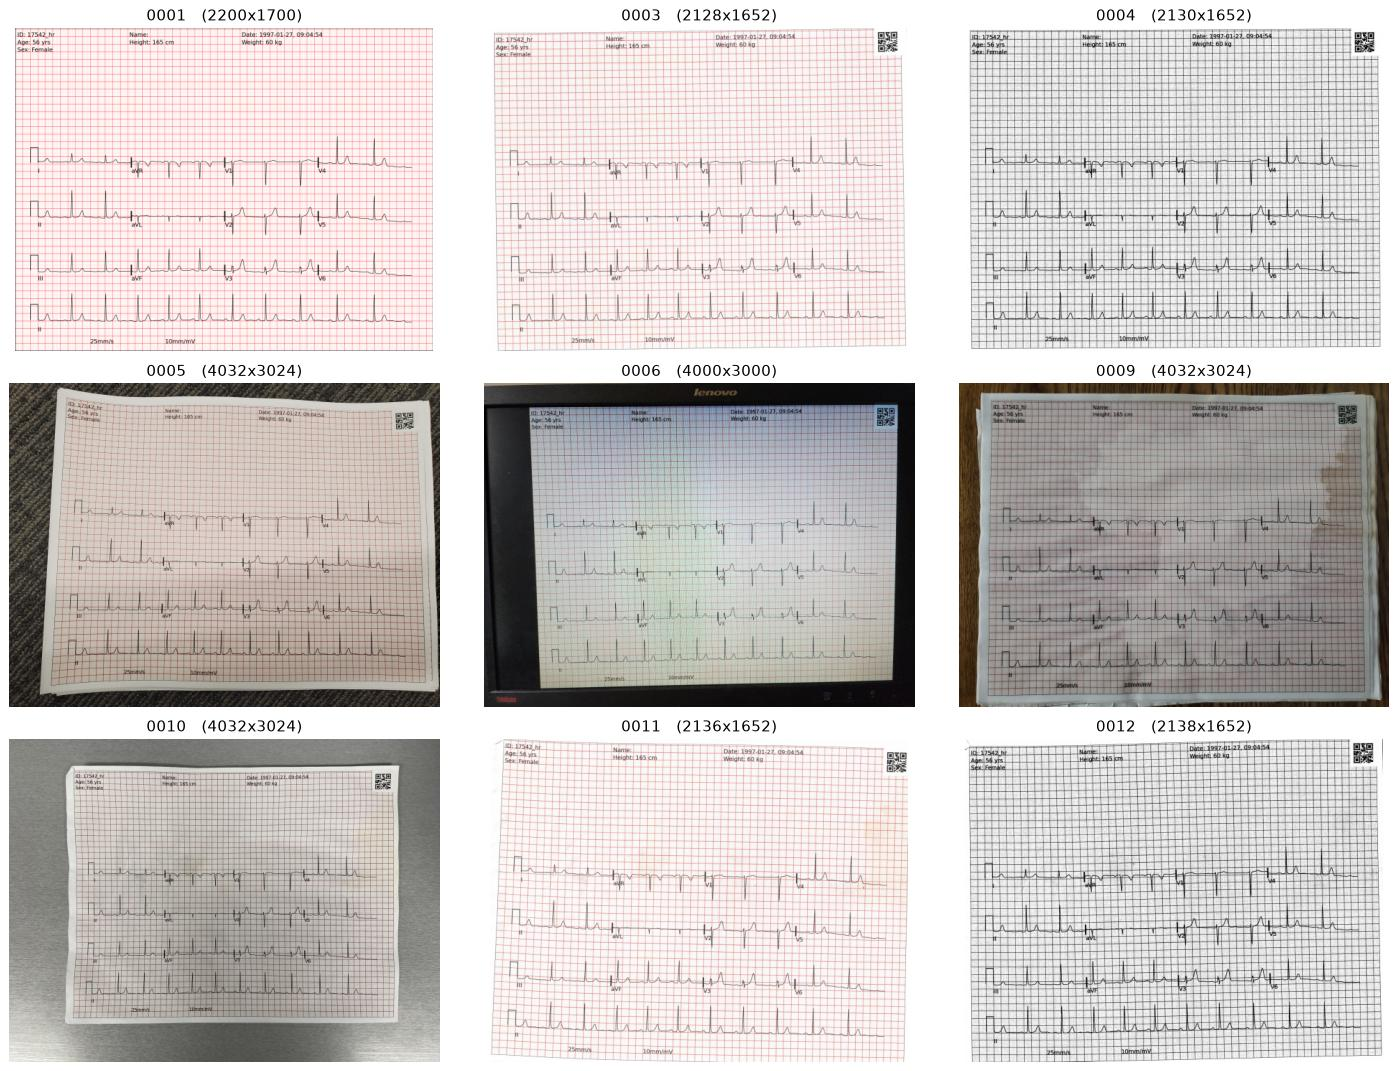

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, t in zip(axes.flat, TYPES):
    img = read_rgb(f'data/competition/train/{RECORD}/{RECORD}-{t}.png')
    ax.imshow(thumb(img, 600)); ax.set_title(f'{t}   ({img.shape[1]}x{img.shape[0]})'); ax.axis('off')
plt.tight_layout(); plt.show()

# Part A: Stages 0-1, preprocessing by hengck23 (reused unchanged)

These stages turn any photo or scan into a standard rectified page. The 2nd-place author did not modify or retrain
them. His training data (`physionet-rectified-images-*`) is their output.

## 2. Stage 0 · *hengck23*: find the page orientation and the lead labels, then remove perspective

Source: `reference/hengck23-demo-submit-physionet/stage0_model.py` and `stage0_common.py`.

* **Model**: a U-Net with a ResNet18d encoder. The image is resized to 1440 px wide, and 4 flipped copies are
  averaged (test-time augmentation).
* **Two outputs**:
  * an 8-way **orientation** classifier (rotations and mirroring); the image is rotated back by the predicted
    multiple of 90°.
  * a per-pixel **marker** map: which lead-name label (`I`, `aVR`, ..., `V6`, 13 classes plus background) each pixel
    belongs to.
* **Keypoints**: the centroid of the largest blob for 9 labels (`aVR, V1, V4, aVL, V2, V5, aVF, V3, V6`). The lead
  names are always printed at the same place on the page, so their positions say where the page is.
* **Homography**: `cv2.findHomography(..., RANSAC)` maps those 9 points onto fixed reference positions, and
  `warpPerspective` produces a 1440 × 1152 **normalised** page. A homography models a *flat* sheet seen from any
  angle. 4 points would define it; 9 points plus RANSAC tolerate a few bad detections.

A homography cannot model curled or wrinkled paper. That is Stage 1's job.

In [4]:
with contextlib.redirect_stdout(io.StringIO()):     # the modules print paths on import
    import stage0_common as s0, stage1_common as s1
    from stage0_model import Net as Stage0Net
    from stage1_model import Net as Stage1Net

def load_net(net, path):
    state = torch.load(path, map_location='cpu', weights_only=True)['state_dict']
    print(path.name, net.load_state_dict(state, strict=False))
    net.eval(); net.output_type = ['infer']
    return net

net0 = load_net(Stage0Net(pretrained=False), HENG / 'weight/stage0-last.checkpoint.pth')
net1 = load_net(Stage1Net(pretrained=False), HENG / 'weight/stage1-last.checkpoint.pth')

stage0-last.checkpoint.pth <All keys matched successfully>


stage1-last.checkpoint.pth <All keys matched successfully>


Stage 0 on CPU: 39s | normalised (1152, 1440, 3) | 9/9 keypoints kept by RANSAC
homography:
 [[ 3.984000e-01  2.490000e-02 -1.683149e+02]
 [-8.100000e-03  4.228000e-01  4.821800e+00]
 [-0.000000e+00  0.000000e+00  1.000000e+00]]


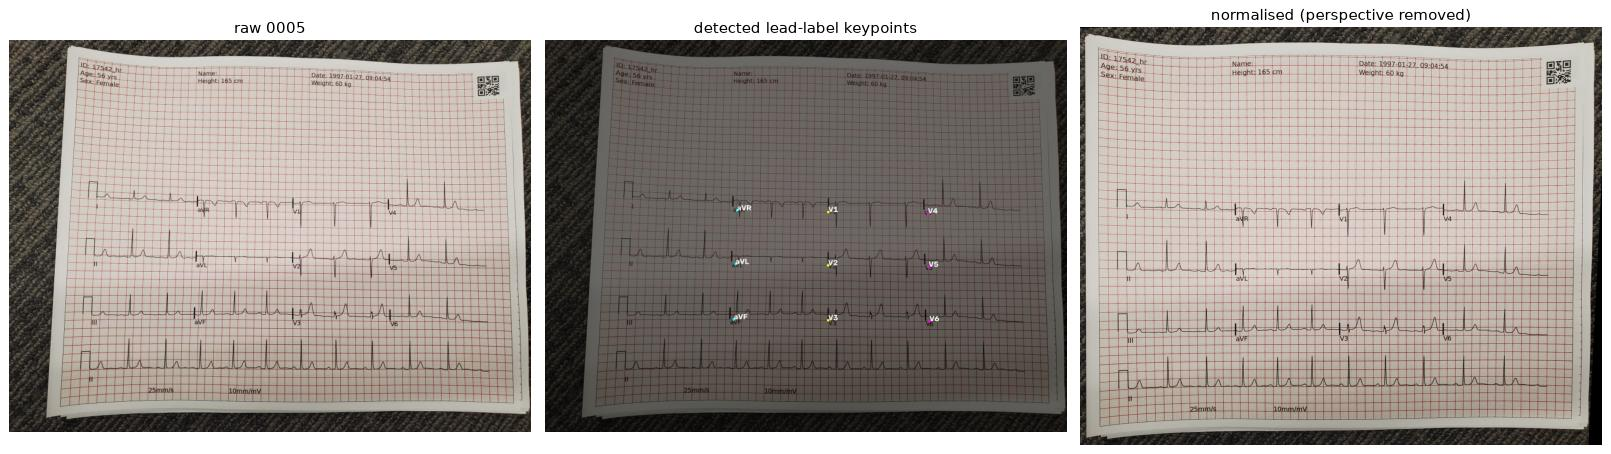

In [5]:
TYPE = '0005'    # the carpet photo: strong perspective. Try '0006', '0009' or '0012' too.
raw = read_rgb(f'data/competition/train/{RECORD}/{RECORD}-{TYPE}.png')

t = time.time()
batch = s0.image_to_batch(raw)                       # resize to 1440 wide, pad, 4 flip TTA copies
with torch.no_grad():
    out0 = net0(batch)
rotated, keypoint = s0.output_to_predict(raw, batch, out0)
normalised, keypoint, homo = s0.normalise_by_homography(rotated, keypoint)
print(f'Stage 0 on CPU: {time.time() - t:.0f}s | normalised {normalised.shape} | '
      f'{sum(k[-1] for k in keypoint)}/9 keypoints kept by RANSAC')
print('homography:\n', np.round(homo, 4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(thumb(raw)); axes[0].set_title(f'raw {TYPE}')
axes[1].imshow(thumb(s0.draw_results_stage0(rotated.copy(), keypoint))); axes[1].set_title('detected lead-label keypoints')
axes[2].imshow(normalised); axes[2].set_title('normalised (perspective removed)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Stage 1 · *hengck23*: detect the grid and un-warp it

Source: `stage1_model.py` and `stage1_common.py`.

* **Model**: a U-Net with a ResNet34 encoder, run on the normalised 1440 × 1152 page.
* **Outputs**:
  * `gridpoint`: a heat-map of the intersections of the bold **5 mm grid lines**.
  * `gridhline` / `gridvline`: for every pixel, *which* horizontal line (1-44) or vertical line (1-57) it lies on.
    This works like semantic segmentation with 45 / 58 classes.
* **Post-processing**: each intersection blob gets an index pair (row `j`, column `i`) from the line maps. That gives
  `gridpoint_xy[44, 57, 2]`, the pixel position of every grid corner; missing ones are filled by cubic interpolation.
* **`rectify_image`**: upsamples this 44 × 57 map to a dense 1700 × 2200 sampling map and calls `grid_sample`. Every
  grid square becomes a perfect square of 2200/56 ≈ 39.3 px (= 5 mm at 200 dpi). Because the map is defined by the
  paper's own grid, it removes **any smooth deformation**: curl, wrinkles, lens distortion.

Stage 1 on CPU: 22s | gridpoint_xy (44, 57, 2) | rectified (1700, 2200, 3)


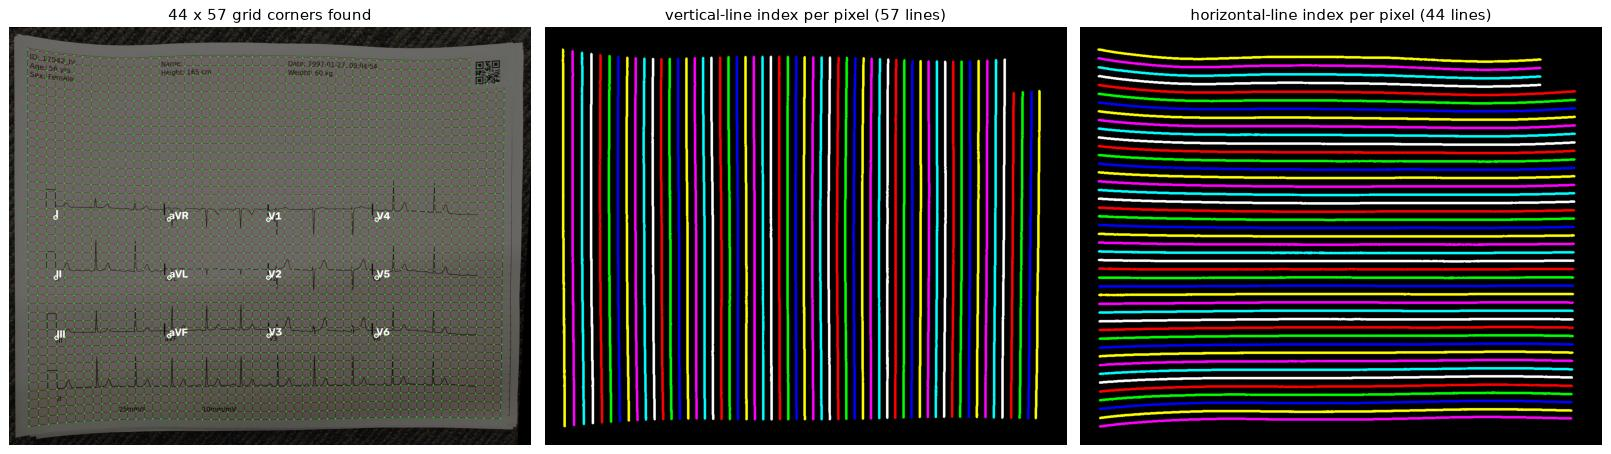

In [6]:
t = time.time()
b1 = {'image': torch.from_numpy(np.ascontiguousarray(normalised.transpose(2, 0, 1))).unsqueeze(0)}
with torch.no_grad():
    out1 = net1(b1)
gridpoint_xy, more = s1.output_to_predict(normalised, b1, out1)
rectified = s1.rectify_image(normalised, gridpoint_xy)
print(f'Stage 1 on CPU: {time.time() - t:.0f}s | gridpoint_xy {gridpoint_xy.shape} | rectified {rectified.shape}')

hlines, vlines = s1.draw_results_stage1(more)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(s1.draw_mapping(normalised, gridpoint_xy)); axes[0].set_title('44 x 57 grid corners found')
axes[1].imshow(hlines); axes[1].set_title('vertical-line index per pixel (57 lines)')
axes[2].imshow(vlines); axes[2].set_title('horizontal-line index per pixel (44 lines)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

mean |ours - author rectified dataset| = 1.95 grey levels (out of 255)


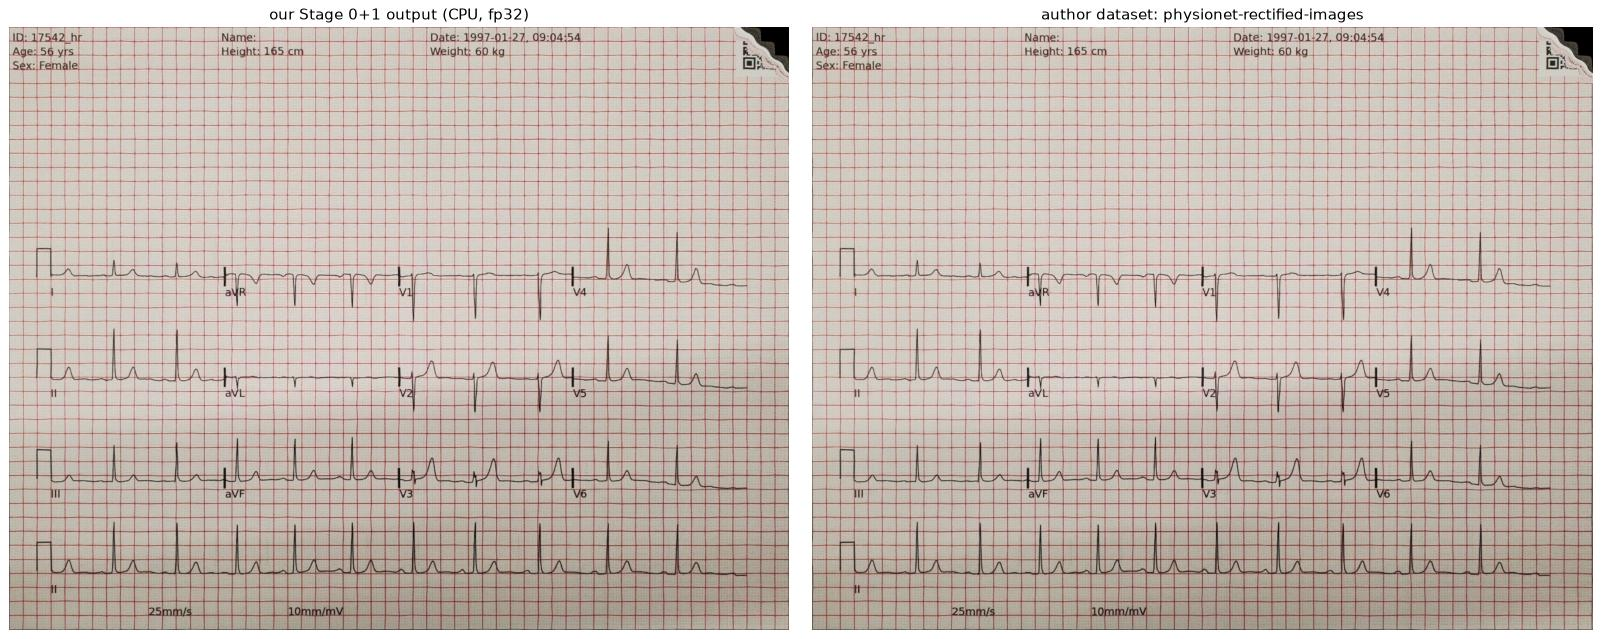

In [7]:
author = read_rgb(f'data/rectified/{RECORD}-{TYPE}.rect.png')
diff = np.abs(rectified.astype(int) - author.astype(int)).mean()
print(f'mean |ours - author rectified dataset| = {diff:.2f} grey levels (out of 255)')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].imshow(rectified); axes[0].set_title('our Stage 0+1 output (CPU, fp32)')
axes[1].imshow(author); axes[1].set_title('author dataset: physionet-rectified-images')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

The two are essentially identical. The small difference is consistent with GPU fp16 versus CPU fp32 arithmetic.
**The author's rectified datasets are exactly this Stage 0+1 output**, which is why Stage 2 can be trained (and
recreated) without touching Stages 0 and 1.

# Part B: Stage 2, the 2nd-place author's work (Takashi Someya)

Everything from here on is the author's own contribution and what this assignment recreates: what the model is
trained to predict (sections 5-6) and how its predictions become signals (section 7). Section 4 is the bridge: the
fixed page geometry that Stage 1 produces and Stage 2 relies on.

## 4. The rectified frame: fixed geometry · *Stage 1 output = Stage 2 input*

Every rectified page is a US-letter sheet at **200 dpi**: 2200 × 1700 px, so 1 mm ≈ 7.87 px. ECG paper runs at
25 mm/s and 10 mm/mV, so on every page:

* **time**: the 10 s of signal span x = 118 ... 2080 (1962 px ≈ 196 px/s)
* **amplitude**: 10 mm/mV ≈ **79 px per mV**
* **baselines (0 mV)** of the 4 rows: y = 703.5, 987.5, 1271.5, 1531.5

Stage 2 hard-codes these numbers (`configs/*.yaml`, `zero_mv`, `mv_to_pixel`, `t0`, `t1`), which only works because
Stage 1 makes every page geometrically identical.

px per mm  = 7.874
px per mV  = 78.7  (config uses 79.0)
px per s   = 196.2


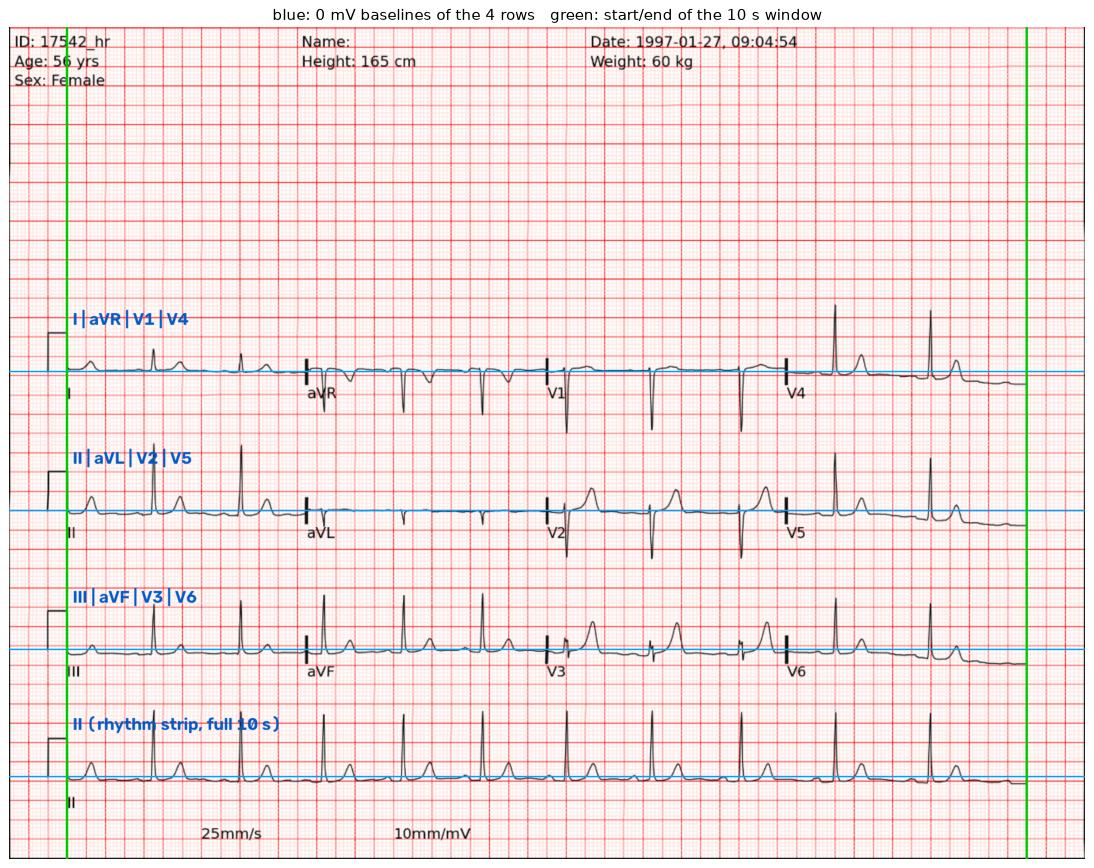

In [8]:
ZERO_MV, MV_TO_PIXEL, X0, X1 = [703.5, 987.5, 1271.5, 1531.5], 79.0, 118, 2080
print(f'px per mm  = {200 / 25.4:.3f}')
print(f'px per mV  = {10 * 200 / 25.4:.1f}  (config uses {MV_TO_PIXEL})')
print(f'px per s   = {(X1 - X0) / 10:.1f}')

img = read_rgb(f'data/rectified/{RECORD}-0001.rect.png').copy()
for y in ZERO_MV:
    cv2.line(img, (0, int(y)), (2199, int(y)), (0, 160, 255), 2)
for x in (X0, X1):
    cv2.line(img, (x, 0), (x, 1699), (0, 200, 0), 3)
rows = ['I | aVR | V1 | V4', 'II | aVL | V2 | V5', 'III | aVF | V3 | V6', 'II (rhythm strip, full 10 s)']
for y, name in zip(ZERO_MV, rows):
    cv2.putText(img, name, (130, int(y) - 95), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 90, 200), 3)
show(img, 'blue: 0 mV baselines of the 4 rows   green: start/end of the 10 s window', size=(16, 12))

## 5. Ground truth: 12 leads to 4 rows · *Stage 2 (Someya)*

The ground-truth CSV has 12 columns (one per lead) at the record's own `fs`. Each of rows 1-3 on the page shows four
leads for 2.5 s each, so a lead is only **non-empty in its quarter**. Lead II appears twice: 2.5 s in row 2, and the
full 10 s in the rhythm strip.

The training code (`Trainer._read_truth_series`) stitches the 12 leads back into the **4 page rows**:

non-empty samples per lead:
I      1250
II     5000
III    1250
aVR    1250
aVL    1250
aVF    1250
V1     1250
V2     1250
V3     1250
V4     1250
V5     1250
V6     1250


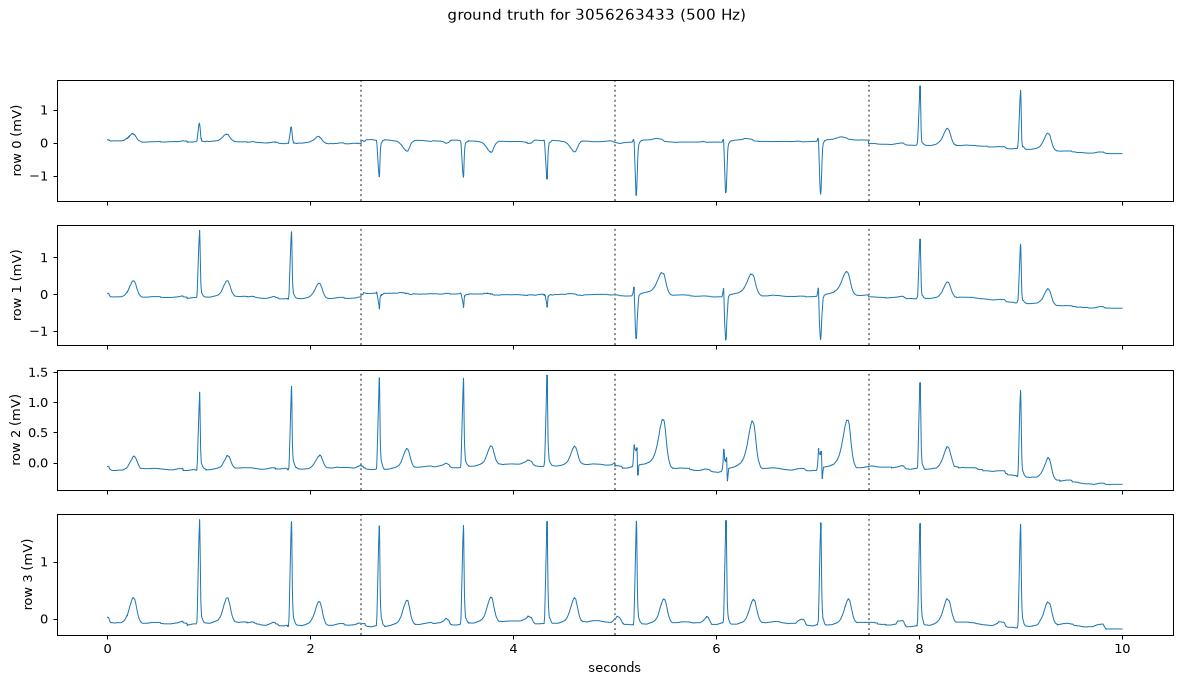

In [9]:
truth = pd.read_csv(f'data/kaggle_ecg_csv/{RECORD}.csv')
print('non-empty samples per lead:'); print(truth.count().to_string())

def truth_rows(df):
    df = df.copy()
    df['II-rhythm'] = df['II']                      # full 10 s
    df.loc[df['I'].isna(), 'II'] = np.nan           # row 2 shows II only in the first quarter
    df = df.fillna(0)
    return np.stack([
        (df['I'] + df['aVR'] + df['V1'] + df['V4']).values,
        (df['II'] + df['aVL'] + df['V2'] + df['V5']).values,
        (df['III'] + df['aVF'] + df['V3'] + df['V6']).values,
        df['II-rhythm'].values,
    ])

gt = truth_rows(truth)
fs = int(train.loc[train.id == RECORD, 'fs'].iloc[0])
t_axis = np.arange(gt.shape[1]) / fs
fig, axes = plt.subplots(4, 1, figsize=(16, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t_axis, gt[i], lw=0.8); ax.set_ylabel(f'row {i} (mV)')
    for q in (2.5, 5, 7.5): ax.axvline(q, color='grey', ls=':')
axes[-1].set_xlabel('seconds'); plt.suptitle(f'ground truth for {RECORD} ({fs} Hz)'); plt.show()

## 6. Training targets: sparse, sub-pixel masks from 500 Hz signals · *Stage 2 (Someya)*

Two of the author's key ideas live in the masks (`data/mask_x5000_500hz_comp_synthesis/{id}.mask-coo.npz`):

1. **Original 500 Hz signals.** The competition signals are PTB-XL resampled to 250-1025 Hz. The author matched every
   record back to the original 500 Hz PTB-XL signal and drew the masks from that. The write-up reports a single-fold
   LB gain of **21.67 to 22.49 dB**.
2. **One column = one 500 Hz sample.** The page is stretched horizontally by `X_SCALE = 5000/1962` so the 10 s
   window covers exactly 5000 columns (x = 301 ... 5300 of a 5600-wide image). There is no resampling inside the
   model.
3. **Sparse sub-pixel labels.** In each column, the trace's exact y (e.g. 704.3) is split over two pixels: 0.7 at
   y=704 and 0.3 at y=705. A probability-weighted mean recovers 704.3 exactly. The write-up says dense (thick)
   masks gave worse SNR.

In [10]:
mask = load_sparse_mask(f'data/mask_x5000_500hz_comp_synthesis/{RECORD}.mask-coo.npz')   # (4, 1696, 5600)
print('mask shape', mask.shape, '| non-zero per row:', [(m > 0).sum() for m in mask])
print(f'X_SCALE = {X_SCALE:.5f} -> resized width {RESIZED_W}, cropped to 5600')

x = 2000
ys = np.nonzero(mask[0][:, x])[0]
print(f'\ncolumn x={x}, row 0: pixels {ys.tolist()} with weights {np.round(mask[0][ys, x], 3).tolist()}')
y_exact = (mask[0][ys, x] * ys).sum()
print(f'weighted mean y = {y_exact:.3f}  ->  {(ZERO_MV[0] - y_exact) / MV_TO_PIXEL:+.3f} mV')

mask shape (4, 1696, 5600) | non-zero per row: [np.int64(10000), np.int64(9998), np.int64(9998), np.int64(10000)]
X_SCALE = 2.54842 -> resized width 5607, cropped to 5600

column x=2000, row 0: pixels [697, 698] with weights [0.8199999928474426, 0.18000000715255737]
weighted mean y = 697.180  ->  +0.080 mV


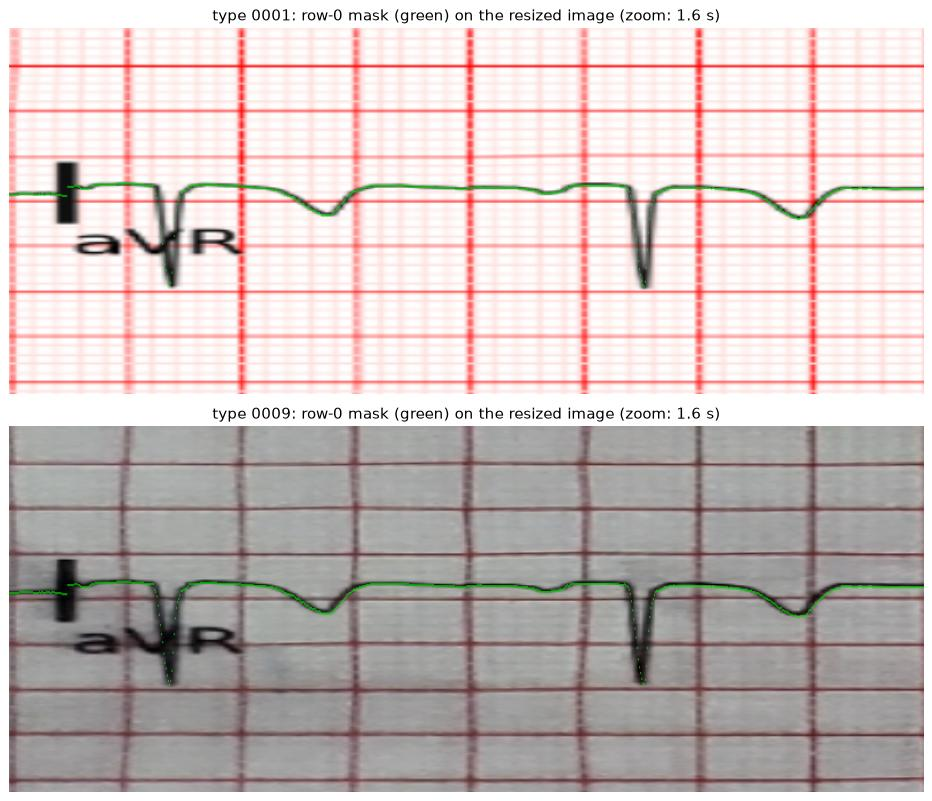

In [11]:
def overlay(type_id, y0=560, y1=880, x0=1500, x1=2300):
    img = resize_rectified(read_rgb(f'data/rectified/{RECORD}-{type_id}.rect.png'))[:1696, :5600]
    crop = img[y0:y1, x0:x1].astype(float) / 255
    m = mask[0, y0:y1, x0:x1]
    out = crop.copy()
    out[m > 0] = 0.4 * out[m > 0] + 0.6 * np.array([0, 0.9, 0])   # green = labelled pixels
    return out

fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for ax, t in zip(axes, ['0001', '0009']):
    ax.imshow(overlay(t)); ax.set_title(f'type {t}: row-0 mask (green) on the resized image (zoom: 1.6 s)'); ax.axis('off')
plt.tight_layout(); plt.show()

The same mask is used for **all 9 image types** of a record. The model must learn to find the trace under stains,
shadows and moiré, but the target is always the clean 500 Hz signal.

## 7. Closing the loop: mask to signal to SNR · *Stage 2 (Someya)*

If the model predicted the mask *perfectly*, the post-processing used in training and inference would give:

1. the weighted mean y per column in x = 301 ... 5300 (5000 values, 500 Hz)
2. `scipy.signal.resample` to the record's `sig_len` (the competition rate)
3. mV = (zero_mv - y) / 79

Comparing that with the ground truth shows the **ceiling** of this target representation.

In [12]:
def mask_to_signal(mask, sig_len, t0=301, t1=5301):
    y = np.arange(mask.shape[1], dtype=np.float32)[:, None]
    p = mask[:, :, t0:t1]
    y_mean = (p * y).sum(1) / np.maximum(p.sum(1), 1e-8)        # (4, 5000)
    y_mean = np.stack([signal.resample(s, sig_len) for s in y_mean])
    return (np.array(ZERO_MV)[:, None] - y_mean) / MV_TO_PIXEL

def snr_db(pred, gt):
    return 10 * np.log10((gt ** 2).sum() / ((pred - gt) ** 2).sum())

for rid in sorted(f[:-4] for f in os.listdir('data/kaggle_ecg_csv')):   # records with ground truth
    row = train[train.id == rid].iloc[0]
    m = load_sparse_mask(f'data/mask_x5000_500hz_comp_synthesis/{rid}.mask-coo.npz')
    pred, g = mask_to_signal(m, row.sig_len), truth_rows(pd.read_csv(f'data/kaggle_ecg_csv/{rid}.csv'))
    print(f'{rid}  fs={row.fs:5d} Hz   perfect-mask SNR per row: ' +
          '  '.join(f'{snr_db(pred[i], g[i]):5.1f}' for i in range(4)) + ' dB')

1195437044  fs=  256 Hz   perfect-mask SNR per row:  40.3   43.5   37.8   41.5 dB


2567450244  fs=  512 Hz   perfect-mask SNR per row:  52.5   51.5   51.3   45.5 dB


3056263433  fs=  500 Hz   perfect-mask SNR per row:  73.5   77.6   76.3   81.3 dB


3554875690  fs=  500 Hz   perfect-mask SNR per row:  73.4   77.7   80.3   91.7 dB


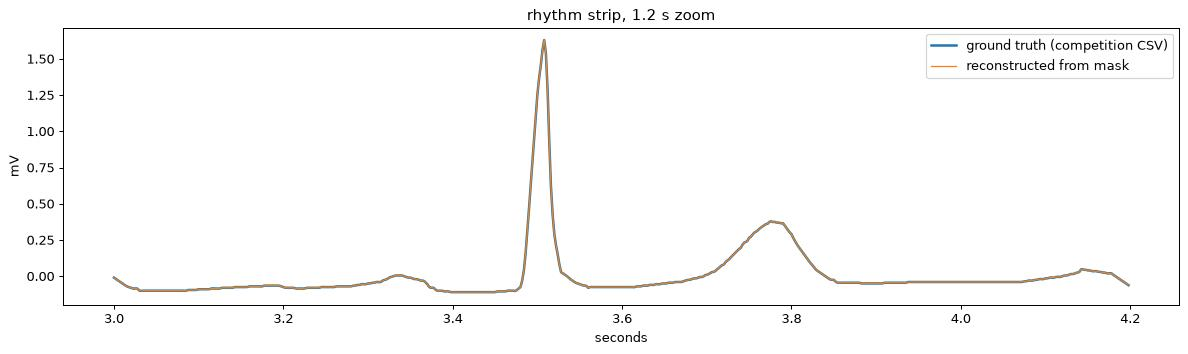

In [13]:
pred = mask_to_signal(mask, gt.shape[1])
sl = slice(int(3.0 * fs), int(4.2 * fs))
plt.figure(figsize=(16, 4))
plt.plot(t_axis[sl], gt[3, sl], lw=2, label='ground truth (competition CSV)')
plt.plot(t_axis[sl], pred[3, sl], lw=1, label='reconstructed from mask')
plt.legend(); plt.xlabel('seconds'); plt.ylabel('mV'); plt.title('rhythm strip, 1.2 s zoom'); plt.show()

**Reading the numbers.** For 500 Hz records the mask reproduces the ground truth almost perfectly (~80 dB). For
records the organisers resampled (e.g. 256 Hz) the ceiling drops to ~40-50 dB, because the mask holds the original
500 Hz signal and we resample it afterwards. That is still far above the ~23 dB the best models reach, so the target
representation is not the bottleneck. Training on the cleaner 500 Hz signal was worth +0.8 dB.

## Check your understanding

1. Why does Stage 0 use the *lead-name labels* as keypoints, rather than the grid?
2. Types 0009/0010 are photos of curled paper. Which stage fixes the curl, and why can't a homography do it?
3. Why does Stage 2 stretch the page to 5600 px wide instead of working at 2200 px?
4. Why split each label over 2 pixels with weights instead of drawing a 1-px (or thick) line?
5. In section 7, why is the perfect-mask SNR lower for 256/512 Hz records, and why was 500 Hz still the right choice?

**Next: Step 2**, how `src/data/dataset_whole.py` and `dataset_series.py` crop these pages and masks for the two
models, and the augmentations.